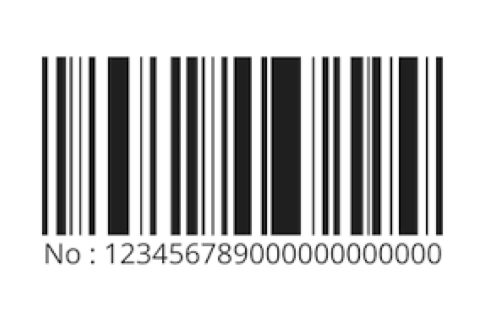

In [7]:
import cv2
import matplotlib.pyplot as plt

img_path = "barkod.2.png"

image = cv2.imread(img_path)

if image is None:
    raise FileNotFoundError(f"Dosya bulunamadı: {img_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Görseli göster
plt.figure(figsize=(6,6))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()


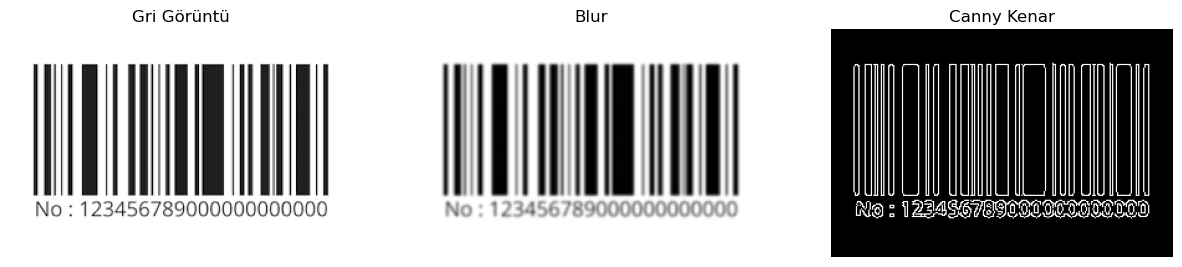

In [8]:
import cv2
import matplotlib.pyplot as plt

img_path = "barkod.2.png"
image = cv2.imread(img_path)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Noise azaltmak için Gaussian Blur
blur = cv2.GaussianBlur(image_gray, (5,5), 0)

# Canny ile kenar tespiti
edges = cv2.Canny(blur, 50, 150)

# Görselleri yan yana göster
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.title("Gri Görüntü")
plt.imshow(image_gray, cmap='gray')
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Blur")
plt.imshow(blur, cmap='gray')
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Canny Kenar")
plt.imshow(edges, cmap='gray')
plt.axis("off")

plt.show()


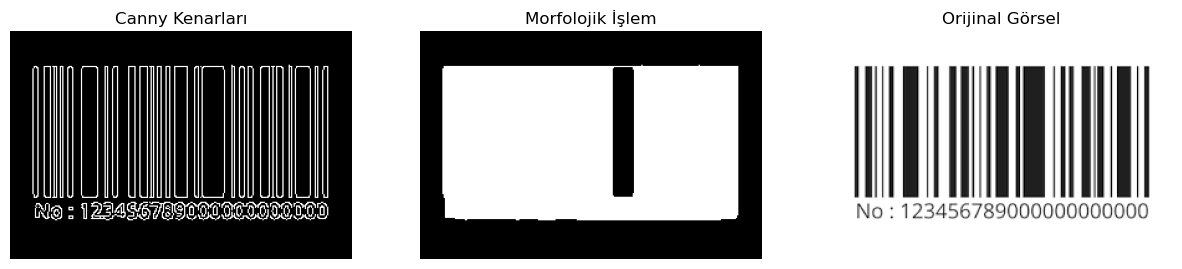

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_path = "barkod.2.png"
image = cv2.imread(img_path)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Blur + kenar
blur = cv2.GaussianBlur(gray, (5,5), 0)
edges = cv2.Canny(blur, 50, 150)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
morph = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.title("Canny Kenarları")
plt.imshow(edges, cmap="gray")
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Morfolojik İşlem")
plt.imshow(morph, cmap="gray")
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Orijinal Görsel")
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")

plt.show()


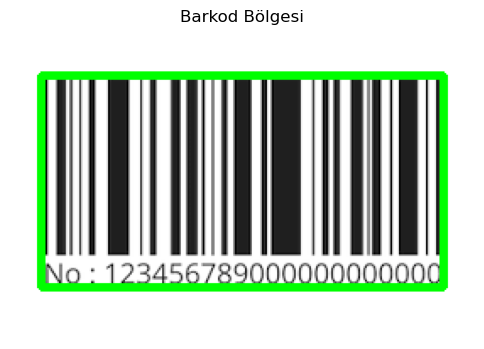

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Görüntü + gri
image = cv2.imread("barkod.2.png")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Blur + edge
blur = cv2.GaussianBlur(gray, (5,5), 0)
edges = cv2.Canny(blur, 50, 150)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
morph = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)


cnts, _ = cv2.findContours(morph, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

cnt = max(cnts, key=cv2.contourArea)

x, y, w, h = cv2.boundingRect(cnt)

output = image.copy()
cv2.rectangle(output, (x, y), (x+w, y+h), (0, 255, 0), 3)

plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Barkod Bölgesi")
plt.axis("off")
plt.show()


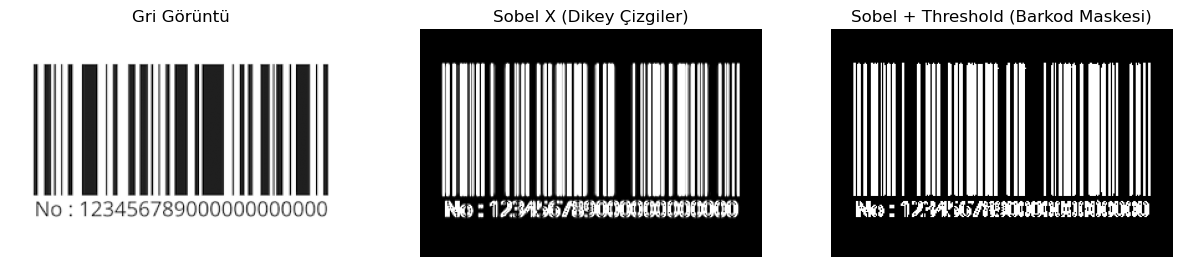

In [11]:
    import cv2
import numpy as np
import matplotlib.pyplot as plt

# Görseli yükle
image = cv2.imread("barkod.2.png")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

sobelX = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobelX = cv2.convertScaleAbs(sobelX)
 
_, thresh = cv2.threshold(sobelX, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.title("Gri Görüntü")
plt.imshow(gray, cmap='gray')
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Sobel X (Dikey Çizgiler)")
plt.imshow(sobelX, cmap='gray')
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Sobel + Threshold (Barkod Maskesi)")
plt.imshow(thresh, cmap='gray')
plt.axis("off")

plt.show()


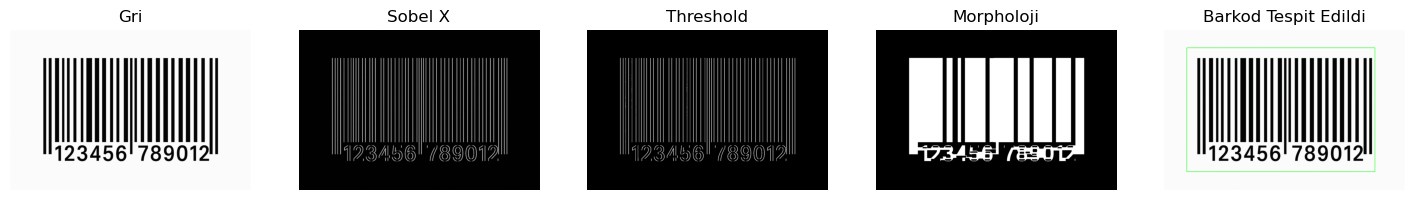

In [31]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def full_barcode_pipeline(image_path):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"❌ Görsel bulunamadı: {image_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobelx = cv2.convertScaleAbs(sobelx)

    _, thresh = cv2.threshold(sobelx, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 7))
    morph = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(morph, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        print("❌ Barkod bulunamadı.")
        return

    largest_contour = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest_contour)


    left_expand = int(w * 0.10)      
    right_expand = int(w * 0.70)    
    expand_h = int(h * 0.10)

    min_width = int(img.shape[1] * 0.65)
    final_width = max(w + left_expand + right_expand, min_width)

    x_new = max(0, x - left_expand)
    y_new = max(0, y - expand_h)

    w_new = min(final_width, img.shape[1] - x_new)
    h_new = h + expand_h * 2

    img_box = img.copy()
    cv2.rectangle(img_box, (x_new, y_new), (x_new + w_new, y_new + h_new), (0, 255, 0), 2)

    images = [gray, sobelx, thresh, morph, img_box]
    titles = ["Gri", "Sobel X", "Threshold", "Morpholoji", "Barkod Tespit Edildi"]

    plt.figure(figsize=(18, 8))
    for i in range(len(images)):
        plt.subplot(1, 5, i + 1)
        if len(images[i].shape) == 2:
            plt.imshow(images[i], cmap='gray')
        else:
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.title(titles[i])
        plt.axis("off")

    plt.show()



full_barcode_pipeline("barkodddd.png")


Okunan Barkod Numarası: 123456789012


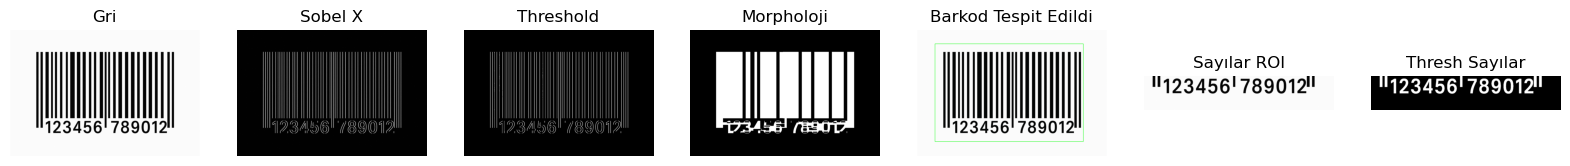

In [47]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract


def full_barcode_with_numbers_pipeline(image_path):
    
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"❌ Görsel bulunamadı: {image_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobelx = cv2.convertScaleAbs(sobelx)

    _, thresh = cv2.threshold(sobelx, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 7))
    morph = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(morph, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        print("❌ Barkod bulunamadı.")
        return

    largest_contour = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest_contour)

    # Barkod kutusunu biraz genişlet
    left_expand = int(w * 0.10)
    right_expand = int(w * 0.70)
    expand_h = int(h * 0.10)

    min_width = int(img.shape[1] * 0.65)
    final_width = max(w + left_expand + right_expand, min_width)

    x_new = max(0, x - left_expand)
    y_new = max(0, y - expand_h)
    w_new = min(final_width, img.shape[1] - x_new)
    h_new = h + expand_h * 2

    img_box = img.copy()
    cv2.rectangle(img_box, (x_new, y_new), (x_new + w_new, y_new + h_new), (0, 255, 0), 2)

    # --- SAYILARI OKUMA ---
    h_img, w_img = gray.shape

    crop_top = int(h_img * 0.70)     # Alt kısmı
    crop_bottom = int(h_img * 0.93)
    crop_left = int(w_img * 0.10)    # Soldan kes
    crop_right = int(w_img * 0.95)   # Sağdan kes

    numbers_roi = gray[crop_top:crop_bottom, crop_left:crop_right]

    _, thresh_numbers = cv2.threshold(numbers_roi, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kernel2 = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    thresh_numbers = cv2.dilate(thresh_numbers, kernel2, iterations=1)

    config = "--psm 7 -c tessedit_char_whitelist=0123456789"
    text = pytesseract.image_to_string(thresh_numbers, config=config)
    digits = "".join(c for c in text if c.isdigit())

    print("Okunan Barkod Numarası:", digits)

    images = [gray, sobelx, thresh, morph, img_box, numbers_roi, thresh_numbers]
    titles = ["Gri", "Sobel X", "Threshold", "Morpholoji", "Barkod Tespit Edildi", "Sayılar ROI", "Thresh Sayılar"]

    plt.figure(figsize=(20, 10))
    for i in range(len(images)):
        plt.subplot(1, len(images), i + 1)
        if len(images[i].shape) == 2:
            plt.imshow(images[i], cmap='gray')
        else:
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.title(titles[i])
        plt.axis("off")
    plt.show()

full_barcode_with_numbers_pipeline("barkodddd.png")


In [13]:
import cv2
import numpy as np

def detect_barcode_camera():
    cap = cv2.VideoCapture(0)

    if not cap.isOpened():
        print("❌ Kamera açılamadı.")
        return

    print("📷 Kamera açıldı. Çıkmak için 'q' bas.")

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        frame = cv2.flip(frame, 1)

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        gray = cv2.GaussianBlur(gray, (5, 5), 0)

        # Sobel X
        sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
        sobelx = cv2.convertScaleAbs(sobelx)

        # Threshold
        _, thresh = cv2.threshold(
            sobelx, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (31, 7))
        morph = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)
        morph = cv2.erode(morph, None, iterations=1)
        morph = cv2.dilate(morph, None, iterations=2)

        contours, _ = cv2.findContours(
            morph, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )

        for c in contours:
            x, y, w, h = cv2.boundingRect(c)

            # 🔍 Barkod benzeri oran filtresi
            aspect_ratio = w / float(h)

            if aspect_ratio > 2.0 and w > 120 and h > 40:
                cv2.rectangle(frame, (x, y),
                              (x + w, y + h),
                              (0, 255, 0), 2)
                cv2.putText(frame, "Barcode detected",
                            (x, y - 10),
                            cv2.FONT_HERSHEY_SIMPLEX,
                            0.7, (0, 255, 0), 2)

        cv2.imshow("Barcode Detection (Camera)", frame)

        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

detect_barcode_camera()


📷 Kamera açıldı. Çıkmak için 'q' bas.


In [51]:
import cv2
from pyzbar.pyzbar import decode

def camera_barcode_reader():
    cap = cv2.VideoCapture(0)

    if not cap.isOpened():
        print("❌ Kamera açılamadı")
        return

    last_barcode = None  # 🔑 en son okunan barkod

    print("📷 Kamera açık | Çıkmak için 'q'")

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        frame = cv2.flip(frame, 1)

        barcodes = decode(frame)

        for barcode in barcodes:
            barcode_data = barcode.data.decode("utf-8")

            if barcode_data != last_barcode:
                print("✔ Okunan Barkod:", barcode_data)
                last_barcode = barcode_data

            x, y, w, h = barcode.rect
            cv2.rectangle(frame, (x, y),
                          (x + w, y + h),
                          (0, 255, 0), 2)

            cv2.putText(frame, barcode_data,
                        (x, y - 10),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.8, (0, 255, 0), 2)

        cv2.imshow("Barcode Reader", frame)

        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

camera_barcode_reader()


📷 Kamera açık | Çıkmak için 'q'
✔ Okunan Barkod: 8690982034678


In [3]:
import cv2
import numpy as np
from pyzbar.pyzbar import decode
import tkinter as tk
from tkinter import filedialog
from PIL import Image, ImageTk

cap = None  

def read_barcode_from_image(image_path):
    img = cv2.imread(image_path)
    if img is None:
        return None

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    resized = cv2.resize(gray, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    blur = cv2.GaussianBlur(resized, (5, 5), 0)
    thresh = cv2.threshold(
        blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )[1]

    for v in [gray, resized, blur, thresh]:
        barcodes = decode(v)
        if barcodes:
            return barcodes[0].data.decode("utf-8")

    return None

def select_image():
    file_path = filedialog.askopenfilename(
        filetypes=[("Image Files", "*.png *.jpg *.jpeg")]
    )
    if not file_path:
        return

    img = Image.open(file_path).resize((320, 220))
    img_tk = ImageTk.PhotoImage(img)
    image_label.config(image=img_tk)
    image_label.image = img_tk

    result = read_barcode_from_image(file_path)
    if result:
        result_label.config(text=f"✅ Okunan Barkod:\n{result}", fg="green")
    else:
        result_label.config(text="❌ Barkod okunamadı", fg="red")


def start_camera():
    global cap
    cap = cv2.VideoCapture(0)

    if not cap.isOpened():
        result_label.config(text="❌ Kamera açılamadı", fg="red")
        return

    result_label.config(text="📷 Kamera açık", fg="blue")
    camera_loop()


def camera_loop():
    global cap

    if cap is None:
        return

    ret, frame = cap.read()
    if not ret:
        return

    frame = cv2.flip(frame, 1)

    barcodes = decode(frame)
    if barcodes:
        b = barcodes[0]
        data = b.data.decode("utf-8")
        x, y, w, h = b.rect

        cv2.rectangle(frame, (x, y), (x + w, y + h),
                      (0, 255, 0), 2)

        cv2.putText(frame, data, (x, y - 10),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7, (0, 255, 0), 2)

        
        result_label.config(text=f"✅ Okunan Barkod:\n{data}", fg="green")

    cv2.imshow("Kamera - Barkod Okuma", frame)

    if cv2.waitKey(1) & 0xFF == ord("q"):
        cap.release()
        cap = None
        cv2.destroyAllWindows()
        return

    root.after(10, camera_loop)


root = tk.Tk()
root.title("Barkod Okuma Sistemi")
root.geometry("420x520")

tk.Label(root, text="BARKOD OKUMA SİSTEMİ",
         font=("Arial", 15, "bold")).pack(pady=10)

tk.Button(root, text="📂 Görselden Barkod Oku",
          font=("Arial", 12),
          width=25,
          command=select_image).pack(pady=10)

tk.Button(root, text="📷 Kameradan Barkod Oku",
          font=("Arial", 12),
          width=25,
          command=start_camera).pack(pady=10)

image_label = tk.Label(root)
image_label.pack(pady=15)

result_label = tk.Label(root,
                        text="Henüz işlem yapılmadı",
                        font=("Arial", 12))
result_label.pack(pady=20)

root.mainloop()
